In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

print("Library berhasil diimport!")

Library berhasil diimport!


In [34]:
df = pd.read_excel("../data/Online Retail.xlsx")

print("UKURAN DATASET")
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

display(df.head())

UKURAN DATASET
Jumlah baris: 541909
Jumlah kolom: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [35]:
print("INFORMASI DATASET")
df.info()

print("\nSTATISTIK DESKRIPTIF")
display(df.describe())

print("\nMISSING VALUES")
display(df.isnull().sum())

INFORMASI DATASET
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

STATISTIK DESKRIPTIF


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



MISSING VALUES


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [36]:
print("PERIODE TRANSAKSI")
print("Awal:", df["InvoiceDate"].min())
print("Akhir:", df["InvoiceDate"].max())

print("\nJUMLAH PRODUK:", df["StockCode"].nunique())

print("\nJUMLAH TRANSAKSI:", df["InvoiceNo"].nunique())

print("\nJUMLAH NEGARA:", df["Country"].nunique())

print("\nTRANSAKSI DENGAN QUANTITY NEGATIF:",
      (df["Quantity"] < 0).sum())

PERIODE TRANSAKSI
Awal: 2010-12-01 08:26:00
Akhir: 2011-12-09 12:50:00

JUMLAH PRODUK: 4070

JUMLAH TRANSAKSI: 25900

JUMLAH NEGARA: 38

TRANSAKSI DENGAN QUANTITY NEGATIF: 10624


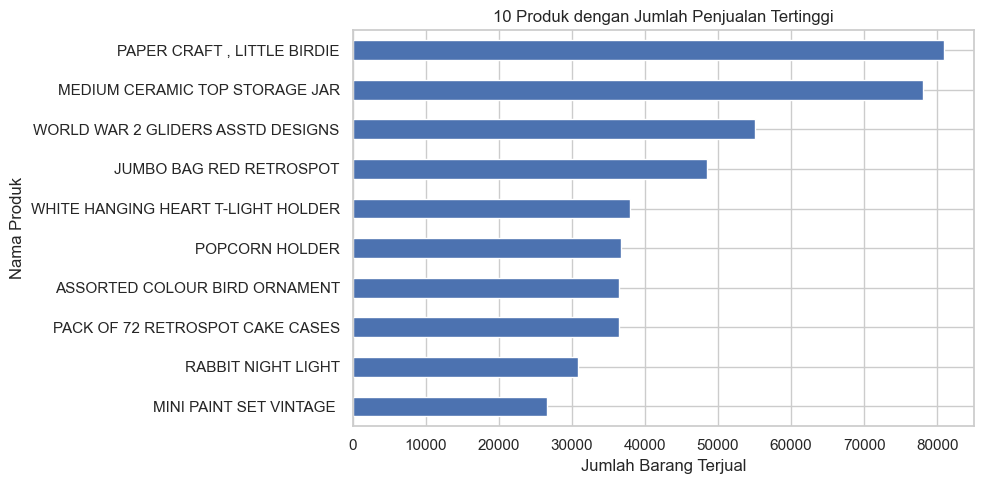

In [37]:
plt.figure(figsize=(10, 5))

top_products = (
    df[df["Quantity"] > 0]
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.sort_values().plot(kind="barh")

plt.title("10 Produk dengan Jumlah Penjualan Tertinggi")
plt.xlabel("Jumlah Barang Terjual")
plt.ylabel("Nama Produk")
plt.tight_layout()
plt.show()

In [38]:
# Membuat salinan dataset
data = df.copy()

# Menghapus data tanpa deskripsi produk
data = data.dropna(subset=["Description"])

# Menghapus transaksi pembatalan dan pengembalian
data = data[data["Quantity"] > 0]

# Menghapus harga yang tidak valid
data = data[data["UnitPrice"] > 0]

# Mengubah format tanggal
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

# Membersihkan spasi pada deskripsi
data["Description"] = data["Description"].str.strip()

print("PREPROCESSING DATASET")
print("Jumlah data sebelum:", len(df))
print("Jumlah data sesudah:", len(data))
print("Jumlah missing values:")
print(data.isnull().sum())

PREPROCESSING DATASET
Jumlah data sebelum: 541909
Jumlah data sesudah: 530104
Jumlah missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132220
Country             0
dtype: int64


In [39]:
# Produk yang dipilih
selected_product = "85099B"

product_data = data[
    data["StockCode"].astype(str) == selected_product
].copy()

print("PRODUK PENELITIAN")
print("Stock Code:", selected_product)
print("Nama Produk:",
      product_data["Description"].iloc[0])

print("Jumlah transaksi:", len(product_data))
print("Total barang terjual:",
      product_data["Quantity"].sum())

print("Jumlah hari transaksi:",
      product_data["InvoiceDate"].dt.date.nunique())

display(product_data.head())

PRODUK PENELITIAN
Stock Code: 85099B
Nama Produk: JUMBO BAG RED RETROSPOT
Jumlah transaksi: 2112
Total barang terjual: 48474
Jumlah hari transaksi: 300


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
177,536386,85099B,JUMBO BAG RED RETROSPOT,100,2010-12-01 09:57:00,1.65,16029.0,United Kingdom
234,536390,85099B,JUMBO BAG RED RETROSPOT,100,2010-12-01 10:19:00,1.65,17511.0,United Kingdom
533,536409,85099B,JUMBO BAG RED RETROSPOT,2,2010-12-01 11:45:00,1.95,17908.0,United Kingdom
790,536464,85099B,JUMBO BAG RED RETROSPOT,1,2010-12-01 12:23:00,1.95,17968.0,United Kingdom
1069,536522,85099B,JUMBO BAG RED RETROSPOT,1,2010-12-01 12:49:00,1.95,15012.0,United Kingdom


In [40]:
# Agregasi permintaan berdasarkan tanggal
daily_demand = (
    product_data
    .groupby(product_data["InvoiceDate"].dt.normalize())
    ["Quantity"]
    .sum()
)

# Membuat rentang tanggal lengkap
date_range = pd.date_range(
    start=daily_demand.index.min(),
    end=daily_demand.index.max(),
    freq="D"
)

# Mengisi hari tanpa transaksi dengan nol
daily_demand = daily_demand.reindex(
    date_range,
    fill_value=0
)

daily_demand = daily_demand.astype(int)

print("DATA PERMINTAAN HARIAN")
print(daily_demand.describe())

display(daily_demand.head(15))

DATA PERMINTAAN HARIAN
count     374.000000
mean      129.609626
std       181.518890
min         0.000000
25%        11.250000
50%        62.000000
75%       161.750000
max      1583.000000
Name: Quantity, dtype: float64


2010-12-01    556
2010-12-02     48
2010-12-03     49
2010-12-04      0
2010-12-05     39
2010-12-06    157
2010-12-07    343
2010-12-08    205
2010-12-09     21
2010-12-10    125
2010-12-11      0
2010-12-12      1
2010-12-13     28
2010-12-14     63
2010-12-15     80
Freq: D, Name: Quantity, dtype: int64

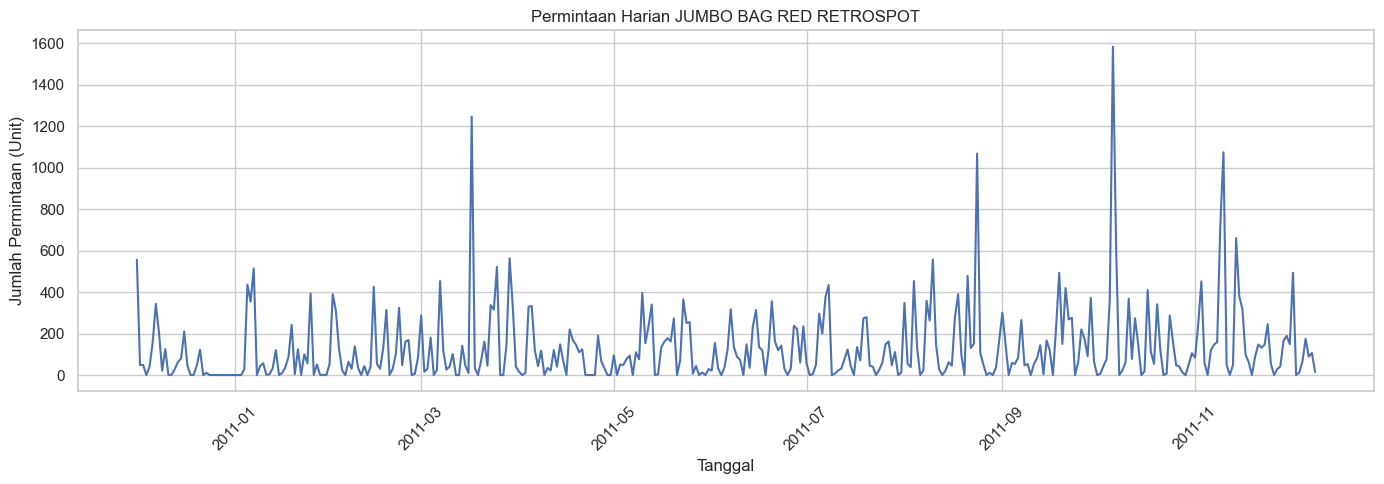

In [41]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_demand.index,
    daily_demand.values
)

plt.title(
    "Permintaan Harian JUMBO BAG RED RETROSPOT"
)

plt.xlabel("Tanggal")
plt.ylabel("Jumlah Permintaan (Unit)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

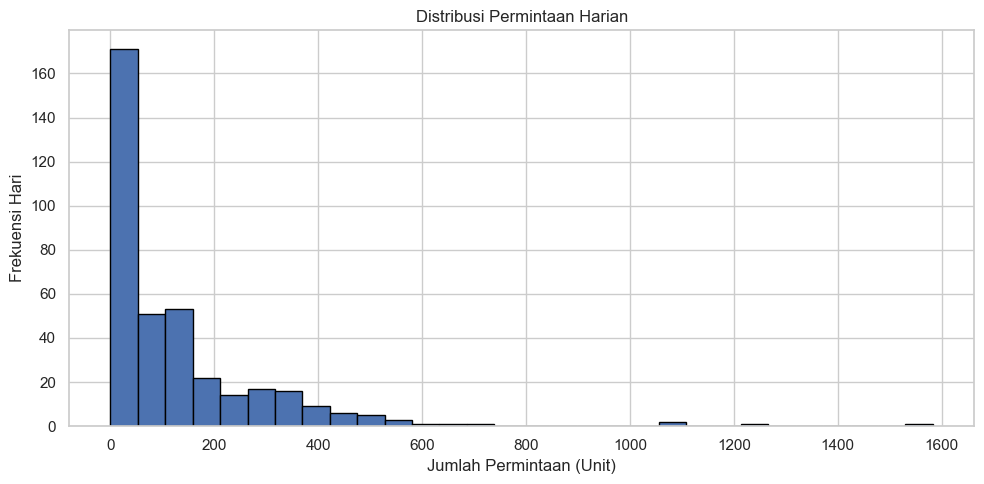

In [42]:
plt.figure(figsize=(10, 5))

plt.hist(
    daily_demand.values,
    bins=30,
    edgecolor="black"
)

plt.title("Distribusi Permintaan Harian")
plt.xlabel("Jumlah Permintaan (Unit)")
plt.ylabel("Frekuensi Hari")

plt.tight_layout()
plt.show()

In [43]:
os.makedirs("../data/processed", exist_ok=True)

processed_data = pd.DataFrame({
    "Date": daily_demand.index,
    "Demand": daily_demand.values
})

processed_data.to_csv(
    "../data/processed/daily_demand.csv",
    index=False
)

print("Dataset hasil preprocessing berhasil disimpan!")
print("Lokasi: data/processed/daily_demand.csv")

Dataset hasil preprocessing berhasil disimpan!
Lokasi: data/processed/daily_demand.csv


In [44]:
# Membuat sinyal permintaan berdasarkan 7 hari sebelumnya
demand_signal = (
    daily_demand.shift(1)
    .rolling(window=7, min_periods=1)
    .mean()
    .fillna(0)
)

# Menghitung batas kategori permintaan
q33 = demand_signal.quantile(0.33)
q66 = demand_signal.quantile(0.66)

def classify_demand(value):
    if value <= q33:
        return "Rendah"
    elif value <= q66:
        return "Sedang"
    else:
        return "Tinggi"

demand_category = demand_signal.apply(classify_demand)

print("BATAS KATEGORI PERMINTAAN")
print("Rendah  :", round(q33, 2))
print("Sedang  :", round(q66, 2))
print("Tinggi  : di atas", round(q66, 2))

print("\nDISTRIBUSI KATEGORI")
print(demand_category.value_counts())

display(pd.DataFrame({
    "Demand": daily_demand,
    "Demand_Signal": demand_signal,
    "Demand_Category": demand_category
}).head(15))

BATAS KATEGORI PERMINTAAN
Rendah  : 95.73
Sedang  : 140.6
Tinggi  : di atas 140.6

DISTRIBUSI KATEGORI
Quantity
Tinggi    127
Rendah    124
Sedang    123
Name: count, dtype: int64


,Demand,Demand_Signal,Demand_Category
2010-12-01,556,0.000000,Rendah
2010-12-02,48,556.000000,Tinggi
2010-12-03,49,302.000000,Tinggi
2010-12-04,0,217.666667,Tinggi
2010-12-05,39,163.250000,Tinggi
2010-12-06,157,138.400000,Sedang
2010-12-07,343,141.500000,Tinggi
2010-12-08,205,170.285714,Tinggi
2010-12-09,21,120.142857,Sedang
2010-12-10,125,116.285714,Sedang


In [45]:
def classify_inventory(stock):
    if stock <= 100:
        return "Rendah"
    elif stock <= 250:
        return "Sedang"
    else:
        return "Tinggi"

inventory_states = [
    "Rendah",
    "Sedang",
    "Tinggi"
]

demand_states = [
    "Rendah",
    "Sedang",
    "Tinggi"
]

# Membentuk seluruh kombinasi state
all_states = []

for inventory in inventory_states:
    for demand in demand_states:
        all_states.append(
            f"Stok_{inventory}_Demand_{demand}"
        )

print("JUMLAH STATE:", len(all_states))

for i, state in enumerate(all_states):
    print(f"S{i}: {state}")

JUMLAH STATE: 9
S0: Stok_Rendah_Demand_Rendah
S1: Stok_Rendah_Demand_Sedang
S2: Stok_Rendah_Demand_Tinggi
S3: Stok_Sedang_Demand_Rendah
S4: Stok_Sedang_Demand_Sedang
S5: Stok_Sedang_Demand_Tinggi
S6: Stok_Tinggi_Demand_Rendah
S7: Stok_Tinggi_Demand_Sedang
S8: Stok_Tinggi_Demand_Tinggi


In [46]:
actions = {
    0: 0,
    1: 100,
    2: 200,
    3: 300
}

print("DAFTAR ACTION")

for action, quantity in actions.items():
    print(f"A{action}: Pesan {quantity} unit")

DAFTAR ACTION
A0: Pesan 0 unit
A1: Pesan 100 unit
A2: Pesan 200 unit
A3: Pesan 300 unit


In [47]:
ENV_CONFIG = {
    "initial_stock": 200,
    "max_capacity": 500,

    "order_fixed_cost": 5.0,
    "order_unit_cost": 0.50,

    "holding_cost": 0.05,
    "stockout_penalty": 2.0,

    "lead_time": 0,

    "max_days": len(daily_demand)
}

print("KONFIGURASI ENVIRONMENT")

for key, value in ENV_CONFIG.items():
    print(f"{key}: {value}")

KONFIGURASI ENVIRONMENT
initial_stock: 200
max_capacity: 500
order_fixed_cost: 5.0
order_unit_cost: 0.5
holding_cost: 0.05
stockout_penalty: 2.0
lead_time: 0
max_days: 374


In [48]:
scenario = {
    "study_case": "Optimasi Pengelolaan Persediaan Barang",
    "product": "JUMBO BAG RED RETROSPOT",
    "stock_code": "85099B",
    "algorithm": "Q-Learning",

    "state": all_states,
    "actions": actions,
    "environment": ENV_CONFIG,

    "demand_thresholds": {
        "q33": float(q33),
        "q66": float(q66)
    }
}

import json

os.makedirs("../data/processed", exist_ok=True)

with open(
    "../data/processed/rl_scenario.json",
    "w"
) as file:
    json.dump(scenario, file, indent=4)

print("Rancangan skenario RL berhasil disimpan!")

Rancangan skenario RL berhasil disimpan!


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os

# Data permintaan harian
demand_values = daily_demand.values.astype(int)

# Pembagian data berdasarkan waktu
split_index = int(len(demand_values) * 0.8)

train_demand = demand_values[:split_index]
test_demand = demand_values[split_index:]

# Sinyal permintaan menggunakan 7 hari sebelumnya
demand_signal = (
    daily_demand.shift(1)
    .rolling(window=7, min_periods=1)
    .mean()
    .fillna(0)
)

# Threshold dihitung dari data training
train_signals = demand_signal.iloc[:split_index]

q33 = train_signals.quantile(0.33)
q66 = train_signals.quantile(0.66)

def classify_demand(value):
    if value <= q33:
        return 0
    elif value <= q66:
        return 1
    return 2

demand_categories = np.array([
    classify_demand(value)
    for value in demand_signal
])

train_categories = demand_categories[:split_index]
test_categories = demand_categories[split_index:]

print("PEMBAGIAN DATA")
print("Total hari       :", len(demand_values))
print("Data training    :", len(train_demand))
print("Data testing     :", len(test_demand))
print("Batas demand 33% :", round(q33, 2))
print("Batas demand 66% :", round(q66, 2))

PEMBAGIAN DATA
Total hari       : 374
Data training    : 299
Data testing     : 75
Batas demand 33% : 86.0
Batas demand 66% : 133.62


In [50]:
class InventoryEnvironment:

    def __init__(
        self,
        demands,
        demand_categories,
        config
    ):
        self.demands = np.array(demands)
        self.demand_categories = np.array(demand_categories)
        self.config = config

        self.actions = [0, 100, 200, 300]

        self.reset()

    def reset(self):

        self.day = 0

        self.stock = self.config["initial_stock"]

        self.total_cost = 0
        self.total_order = 0
        self.total_sold = 0
        self.total_shortage = 0

        self.history = []

        return self.get_state()

    def get_inventory_category(self):

        if self.stock <= 100:
            return 0
        elif self.stock <= 250:
            return 1
        else:
            return 2

    def get_state(self):

        inventory_state = self.get_inventory_category()

        demand_state = int(
            self.demand_categories[self.day]
        )

        return inventory_state * 3 + demand_state

    def step(self, action_index):

        order_quantity = self.actions[action_index]

        # Menyesuaikan pesanan dengan kapasitas gudang
        actual_order = min(
            order_quantity,
            self.config["max_capacity"] - self.stock
        )

        # Biaya pemesanan
        order_cost = 0

        if actual_order > 0:
            order_cost = (
                self.config["order_fixed_cost"]
                + actual_order * self.config["order_unit_cost"]
            )

        # Barang tersedia untuk memenuhi permintaan
        available_stock = self.stock + actual_order

        demand = int(self.demands[self.day])

        # Penjualan aktual
        sold = min(available_stock, demand)

        # Kekurangan stok
        shortage = max(0, demand - available_stock)

        # Persediaan akhir
        ending_stock = available_stock - sold

        # Biaya penyimpanan
        holding_cost = (
            ending_stock * self.config["holding_cost"]
        )

        # Penalti kekurangan stok
        shortage_cost = (
            shortage * self.config["stockout_penalty"]
        )

        # Total biaya
        total_cost = (
            order_cost
            + holding_cost
            + shortage_cost
        )

        # Reward negatif dari total biaya
        reward = -total_cost

        # Memperbarui persediaan
        self.stock = ending_stock

        self.total_cost += total_cost
        self.total_order += actual_order
        self.total_sold += sold
        self.total_shortage += shortage

        self.history.append({
            "Day": self.day + 1,
            "Demand": demand,
            "Order": actual_order,
            "Available_Stock": available_stock,
            "Sold": sold,
            "Ending_Stock": ending_stock,
            "Shortage": shortage,
            "Order_Cost": order_cost,
            "Holding_Cost": holding_cost,
            "Shortage_Cost": shortage_cost,
            "Total_Cost": total_cost,
            "Reward": reward
        })

        self.day += 1

        done = self.day >= len(self.demands)

        next_state = None if done else self.get_state()

        return next_state, reward, done

In [51]:
env = InventoryEnvironment(
    train_demand,
    train_categories,
    ENV_CONFIG
)

state = env.reset()

print("PENGUJIAN ENVIRONMENT")
print("State awal:", state)
print("Stok awal:", env.stock)

next_state, reward, done = env.step(2)

print("\nHASIL SATU LANGKAH SIMULASI")
print("Next State:", next_state)
print("Reward:", reward)
print("Done:", done)
print("Stok akhir:", env.stock)

display(pd.DataFrame(env.history))

PENGUJIAN ENVIRONMENT
State awal: 3
Stok awal: 200

HASIL SATU LANGKAH SIMULASI
Next State: 2
Reward: -417.0
Done: False
Stok akhir: 0


,Day,Demand,Order,Available_Stock,Sold,Ending_Stock,Shortage,Order_Cost,Holding_Cost,Shortage_Cost,Total_Cost,Reward
0,1,556,200,400,400,0,156,105.0,0.0,312.0,417.0,-417.0


In [52]:
# Jumlah state = 9
# Jumlah action = 4

n_states = 9
n_actions = 4

Q_table = np.zeros((n_states, n_actions))

learning_rate = 0.1
discount_factor = 0.95

epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995

episodes = 1000

print("Q-TABLE BERHASIL DIBUAT")
print("Ukuran:", Q_table.shape)

display(pd.DataFrame(
    Q_table,
    columns=["Tidak Pesan", "Pesan 100", "Pesan 200", "Pesan 300"],
    index=[f"S{i}" for i in range(n_states)]
))

Q-TABLE BERHASIL DIBUAT
Ukuran: (9, 4)


,Tidak Pesan,Pesan 100,Pesan 200,Pesan 300
S0,0.0,0.0,0.0,0.0
S1,0.0,0.0,0.0,0.0
S2,0.0,0.0,0.0,0.0
S3,0.0,0.0,0.0,0.0
S4,0.0,0.0,0.0,0.0
S5,0.0,0.0,0.0,0.0
S6,0.0,0.0,0.0,0.0
S7,0.0,0.0,0.0,0.0
S8,0.0,0.0,0.0,0.0


In [53]:
env = InventoryEnvironment(
    train_demand,
    train_categories,
    ENV_CONFIG
)

episode_rewards = []
episode_costs = []

for episode in range(episodes):

    state = env.reset()

    total_reward = 0

    done = False

    while not done:

        # Epsilon-greedy action selection
        if random.random() < epsilon:
            action = random.randint(0, n_actions - 1)
        else:
            action = np.argmax(Q_table[state])

        # Menjalankan tindakan
        next_state, reward, done = env.step(action)

        # Update Q-Table
        old_value = Q_table[state, action]

        if done:
            target = reward
        else:
            target = (
                reward
                + discount_factor
                * np.max(Q_table[next_state])
            )

        Q_table[state, action] = (
            old_value
            + learning_rate
            * (target - old_value)
        )

        state = next_state

        total_reward += reward

    episode_rewards.append(total_reward)
    episode_costs.append(env.total_cost)

    # Mengurangi eksplorasi secara bertahap
    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

    if (episode + 1) % 100 == 0:
        print(
            f"Episode {episode + 1}/{episodes} | "
            f"Reward: {total_reward:.2f} | "
            f"Cost: {env.total_cost:.2f} | "
            f"Epsilon: {epsilon:.4f}"
        )

print("\nTRAINING SELESAI!")

Episode 100/1000 | Reward: -31641.80 | Cost: 31641.80 | Epsilon: 0.6058
Episode 200/1000 | Reward: -29092.00 | Cost: 29092.00 | Epsilon: 0.3670
Episode 300/1000 | Reward: -28598.05 | Cost: 28598.05 | Epsilon: 0.2223
Episode 400/1000 | Reward: -32205.30 | Cost: 32205.30 | Epsilon: 0.1347
Episode 500/1000 | Reward: -28225.10 | Cost: 28225.10 | Epsilon: 0.0816
Episode 600/1000 | Reward: -28192.95 | Cost: 28192.95 | Epsilon: 0.0494
Episode 700/1000 | Reward: -28337.40 | Cost: 28337.40 | Epsilon: 0.0299
Episode 800/1000 | Reward: -27152.55 | Cost: 27152.55 | Epsilon: 0.0181
Episode 900/1000 | Reward: -27197.50 | Cost: 27197.50 | Epsilon: 0.0110
Episode 1000/1000 | Reward: -27844.35 | Cost: 27844.35 | Epsilon: 0.0100

TRAINING SELESAI!


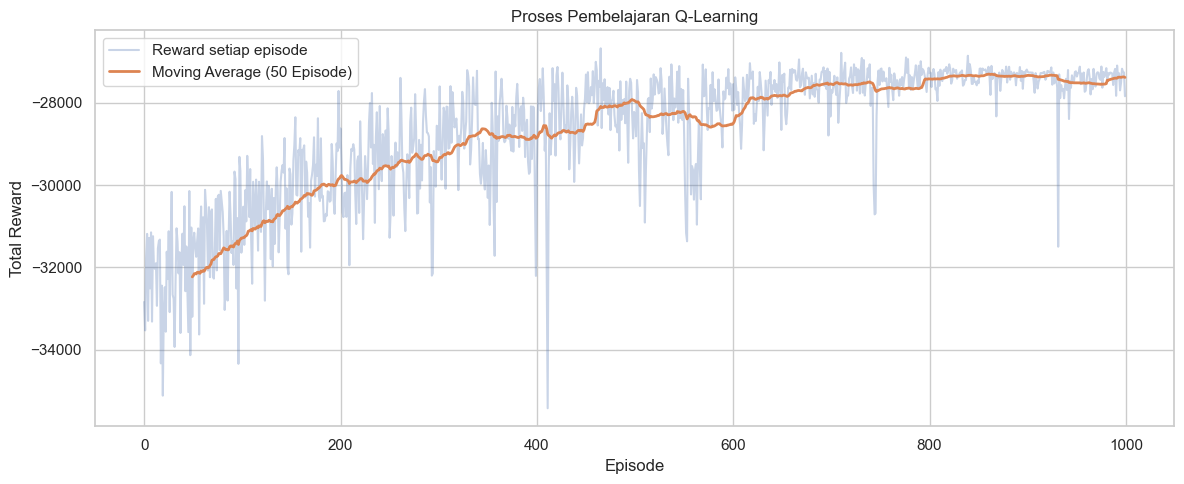

In [54]:
plt.figure(figsize=(12, 5))

plt.plot(
    episode_rewards,
    alpha=0.3,
    label="Reward setiap episode"
)

window = 50

if len(episode_rewards) >= window:
    moving_average = pd.Series(
        episode_rewards
    ).rolling(window).mean()

    plt.plot(
        moving_average,
        label="Moving Average (50 Episode)",
        linewidth=2
    )

plt.title("Proses Pembelajaran Q-Learning")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.legend()
plt.tight_layout()
plt.show()

HASIL Q-TABLE SETELAH TRAINING


,Tidak Pesan,Pesan 100,Pesan 200,Pesan 300
S0,-2211.17,-2017.15,-1990.31,-1959.68
S1,-1985.71,-2002.11,-2004.84,-1900.12
S2,-2011.64,-1783.55,-2000.07,-2043.85
S3,-1996.52,-2024.56,-1945.54,-1917.76
S4,-1824.98,-1830.78,-1756.80,-1802.30
S5,-1785.44,-2015.76,-1949.33,-1884.01
S6,-1835.95,-1798.07,-1796.57,-1673.99
S7,-1783.13,-1764.10,-1740.94,-1739.58
S8,-1805.27,-1812.86,-1693.32,-1805.40


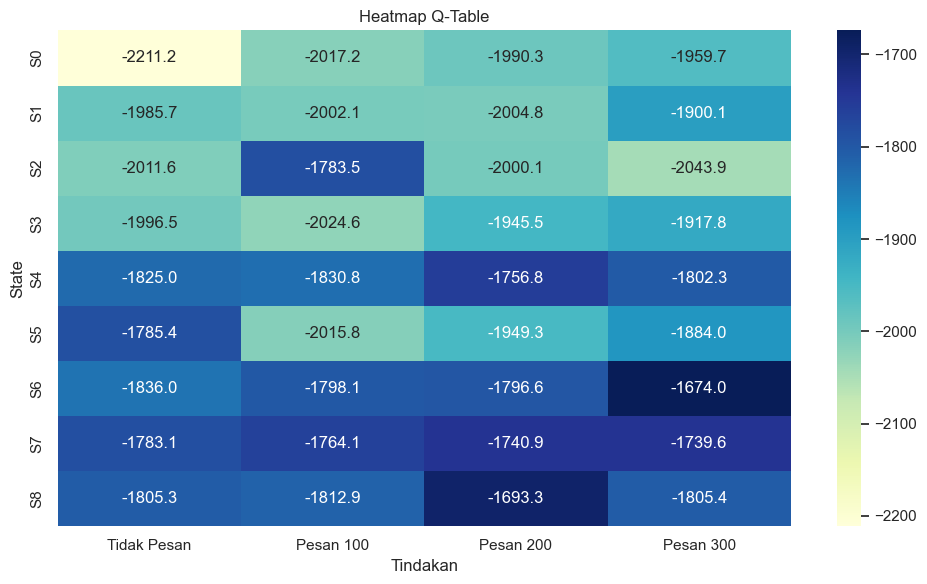

In [55]:
Q_result = pd.DataFrame(
    Q_table,
    columns=[
        "Tidak Pesan",
        "Pesan 100",
        "Pesan 200",
        "Pesan 300"
    ],
    index=[f"S{i}" for i in range(n_states)]
)

print("HASIL Q-TABLE SETELAH TRAINING")

display(Q_result.round(2))

plt.figure(figsize=(10, 6))

sns.heatmap(
    Q_result,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Heatmap Q-Table")
plt.xlabel("Tindakan")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [56]:
def evaluate_q_learning(
    demands,
    categories,
    q_table
):

    test_env = InventoryEnvironment(
        demands,
        categories,
        ENV_CONFIG
    )

    state = test_env.reset()

    done = False

    while not done:

        action = np.argmax(q_table[state])

        next_state, reward, done = test_env.step(action)

        state = next_state

    return pd.DataFrame(test_env.history)


q_result = evaluate_q_learning(
    test_demand,
    test_categories,
    Q_table
)

print("HASIL EVALUASI Q-LEARNING")

display(q_result.head(10))

print("\nTotal biaya:",
      round(q_result["Total_Cost"].sum(), 2))

print("Total pemesanan:",
      q_result["Order"].sum())

print("Total penjualan:",
      q_result["Sold"].sum())

print("Total kekurangan stok:",
      q_result["Shortage"].sum())

HASIL EVALUASI Q-LEARNING


,Day,Demand,Order,Available_Stock,Sold,Ending_Stock,Shortage,Order_Cost,Holding_Cost,Shortage_Cost,Total_Cost,Reward
0,1,220,0,200,200,0,20,0.0,0.00,40.0,40.00,-40.00
1,2,174,100,100,100,0,74,55.0,0.00,148.0,203.00,-203.00
2,3,91,100,100,91,9,0,55.0,0.45,0.0,55.45,-55.45
3,4,372,100,109,109,0,263,55.0,0.00,526.0,581.00,-581.00
4,5,66,100,100,66,34,0,55.0,1.70,0.0,56.70,-56.70
5,6,0,100,134,0,134,0,55.0,6.70,0.0,61.70,-61.70
6,7,6,0,134,6,128,0,0.0,6.40,0.0,6.40,-6.40
7,8,43,200,328,43,285,0,105.0,14.25,0.0,119.25,-119.25
8,9,77,215,500,77,423,0,112.5,21.15,0.0,133.65,-133.65
9,10,361,77,500,361,139,0,43.5,6.95,0.0,50.45,-50.45



Total biaya: 16206.85
Total pemesanan: 7357
Total penjualan: 7467
Total kekurangan stok: 5882


In [57]:
def evaluate_baseline(
    demands,
    categories,
    policy
):

    baseline_env = InventoryEnvironment(
        demands,
        categories,
        ENV_CONFIG
    )

    state = baseline_env.reset()
    done = False

    while not done:

        action = policy(
            baseline_env.stock,
            state
        )

        next_state, reward, done = baseline_env.step(action)

        state = next_state

    return pd.DataFrame(baseline_env.history)


# Kebijakan tanpa pemesanan
def no_order_policy(stock, state):
    return 0


# Kebijakan reorder point
def reorder_policy(stock, state):

    if stock <= 100:
        return 3
    elif stock <= 200:
        return 2
    else:
        return 0


no_order_result = evaluate_baseline(
    test_demand,
    test_categories,
    no_order_policy
)

reorder_result = evaluate_baseline(
    test_demand,
    test_categories,
    reorder_policy
)

print("EVALUASI METODE PEMBANDING SELESAI")

EVALUASI METODE PEMBANDING SELESAI


In [58]:
def calculate_metrics(result):

    total_demand = result["Demand"].sum()
    total_sold = result["Sold"].sum()
    total_shortage = result["Shortage"].sum()

    fill_rate = (
        total_sold / total_demand * 100
        if total_demand > 0 else 0
    )

    return {
        "Total Biaya": result["Total_Cost"].sum(),
        "Total Pemesanan": result["Order"].sum(),
        "Total Penjualan": total_sold,
        "Total Stockout": total_shortage,
        "Rata-rata Stok": result["Ending_Stock"].mean(),
        "Fill Rate (%)": fill_rate
    }


comparison = pd.DataFrame({
    "Tanpa Pemesanan": calculate_metrics(no_order_result),
    "Reorder Point": calculate_metrics(reorder_result),
    "Q-Learning": calculate_metrics(q_result)
}).T

print("PERBANDINGAN HASIL EVALUASI")

display(comparison.round(2))

PERBANDINGAN HASIL EVALUASI


,Total Biaya,Total Pemesanan,Total Penjualan,Total Stockout,Rata-rata Stok,Fill Rate (%)
Tanpa Pemesanan,26298.00,0.0,200.0,13149.0,0.00,1.50
Reorder Point,13719.95,9400.0,9263.0,4086.0,176.79,69.39
Q-Learning,16206.85,7357.0,7467.0,5882.0,123.83,55.94


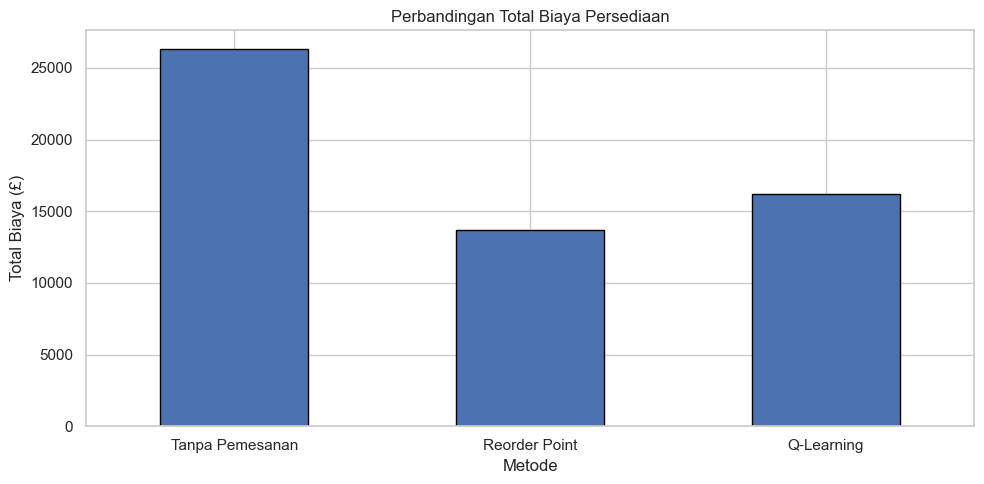

In [59]:
plt.figure(figsize=(10, 5))

comparison["Total Biaya"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Perbandingan Total Biaya Persediaan")
plt.xlabel("Metode")
plt.ylabel("Total Biaya (£)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

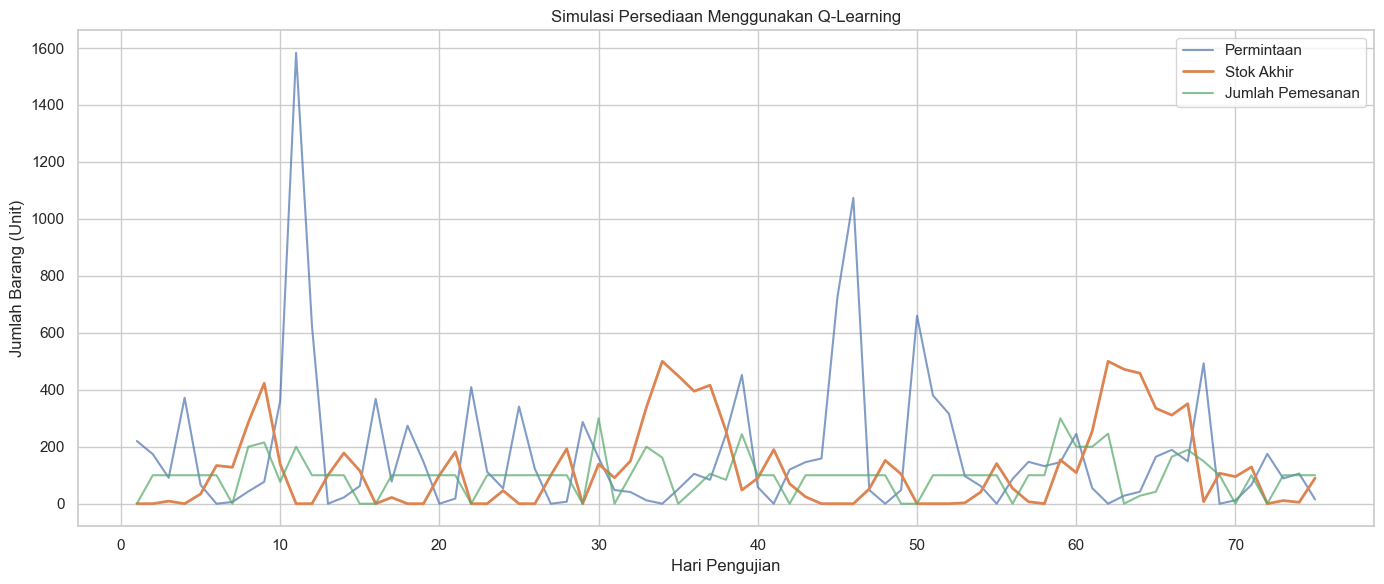

In [60]:
plt.figure(figsize=(14, 6))

plt.plot(
    q_result["Day"],
    q_result["Demand"],
    label="Permintaan",
    alpha=0.7
)

plt.plot(
    q_result["Day"],
    q_result["Ending_Stock"],
    label="Stok Akhir",
    linewidth=2
)

plt.plot(
    q_result["Day"],
    q_result["Order"],
    label="Jumlah Pemesanan",
    alpha=0.7
)

plt.title("Simulasi Persediaan Menggunakan Q-Learning")
plt.xlabel("Hari Pengujian")
plt.ylabel("Jumlah Barang (Unit)")
plt.legend()

plt.tight_layout()
plt.show()

In [61]:
os.makedirs("../results", exist_ok=True)
os.makedirs("../models", exist_ok=True)

# Menyimpan Q-Table
np.save("../models/q_table.npy", Q_table)

# Menyimpan hasil simulasi
q_result.to_csv(
    "../results/q_learning_results.csv",
    index=False
)

no_order_result.to_csv(
    "../results/no_order_results.csv",
    index=False
)

reorder_result.to_csv(
    "../results/reorder_point_results.csv",
    index=False
)

comparison.to_csv(
    "../results/comparison_results.csv"
)

# Menyimpan riwayat training
training_history = pd.DataFrame({
    "Episode": range(1, episodes + 1),
    "Reward": episode_rewards,
    "Cost": episode_costs
})

training_history.to_csv(
    "../results/training_history.csv",
    index=False
)

print("SEMUA HASIL BERHASIL DISIMPAN!")

SEMUA HASIL BERHASIL DISIMPAN!
